# So sánh không gian latent của 3 mô hình: VAE · ViT · V-JEPA 2



## Cell 0 — Chọn đầu vào & thiết lập môi trường

In [26]:
# ===================== CHỌN ĐẦU VÀO =====================
# INPUT = "anh"   -> xử lý ảnh  IMAGE_PATH
# INPUT = "video" -> xử lý video VIDEO_PATH
INPUT      = "video"
IMAGE_PATH = "input1.jpg"
VIDEO_PATH = "video.MOV"
# ========================================================

import os, time, math, warnings
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")   # giảm phân mảnh VRAM (GPU 4GB)
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import cv2
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from PIL import Image, ImageOps
from sklearn.decomposition import PCA
from diffusers import AutoencoderKL
from transformers import ViTForImageClassification, VJEPA2Model

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 10})

# Chuẩn hoá giá trị INPUT: chấp nhận "anh", "ảnh", "image", "video"
_ALIAS = {"anh": "image", "ảnh": "image", "image": "image", "video": "video"}
assert INPUT.strip().lower() in _ALIAS, f'INPUT phải là "anh" hoặc "video", đang là {INPUT!r}'
KIND = _ALIAS[INPUT.strip().lower()]
IS_VIDEO = KIND == "video"
assert os.path.exists(VIDEO_PATH if IS_VIDEO else IMAGE_PATH), "Không tìm thấy file đầu vào"

# Model đã tải về máy (offline, không cần internet)
MODEL_DIR = {
    "VAE":      "models/vae-sd-ft-mse",
    "ViT":      "models/vit-base-patch16-224",
    "V-JEPA 2": "models/vjepa2-vitl-fpc64-256",
}
MODELS = list(MODEL_DIR)                     # thứ tự cố định khi vẽ / so sánh

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE  = torch.float16 if DEVICE == "cuda" else torch.float32   # fp16 để vừa GPU 4GB
NUM_FRAMES = 16          # số khung lấy từ video (V-JEPA 2 gộp 2 khung/tubelet → 8 bước thời gian)
torch.manual_seed(0); np.random.seed(0)

print(f"Đầu vào: {KIND.upper()} -> {VIDEO_PATH if IS_VIDEO else IMAGE_PATH}")
print("torch", torch.__version__, "| device:", DEVICE,
      f"({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else "")

Đầu vào: VIDEO -> video.MOV
torch 2.14.1+cu126 | device: cuda (Quadro T2000)


## Cell 1 — Tiền xử lý ảnh / video cho khớp đầu vào từng mô hình

Mỗi mô hình được huấn luyện với một **kích thước** và **chuẩn hoá** riêng, nên phải biến đổi $X$ cho đúng:

| Mô hình | Resize | Chuẩn hoá pixel | Tensor đầu vào (`anh`) | Tensor đầu vào (`video`, 16 khung) |
|---|---|---|---|---|
| VAE | 256×256 (bội số của 8) | $[0,1] \rightarrow [-1,1]$ (mean = std = 0.5) | `(1, 3, 256, 256)` | `(16, 3, 256, 256)` – từng khung là 1 ảnh |
| ViT | 224×224 (14×14 patch 16px) | mean = std = 0.5 | `(1, 3, 224, 224)` | `(16, 3, 224, 224)` – từng khung là 1 ảnh |
| V-JEPA 2 | 256×256 (16×16 patch 16px) | ImageNet mean/std | `(1, 16, 3, 256, 256)` – ảnh lặp lại 16 lần thành video tĩnh | `(1, 16, 3, 256, 256)` – `(B, T, C, H, W)` |

**Ghi chú**
* Ảnh / video gốc thường **không vuông**, nên ta cắt **hình vuông ở giữa** (center crop) rồi mới resize.
  Cả 3 mô hình nhìn **cùng một vùng ảnh** ⇒ bản đồ latent của chúng chồng khớp được với nhau khi so sánh.
  (Bản gốc của V-JEPA 2 resize cạnh ngắn 292 rồi crop 256; ở đây giữ nguyên vùng nhìn để so sánh công bằng.)
* Video: lấy **16 khung cách đều** trên toàn bộ clip. V-JEPA 2 nhận nguyên khối 16 khung; VAE & ViT là mô hình ảnh nên xử lý từng khung riêng.



Video   : 1080x1920 @ 60.0 fps, lấy 16 khung: [0, 60, 120, 180, 240, 300, 360, 420, 481, 541, 601, 661, 721, 781, 841, 901]
Crop vuông: 1080x1080



,model,đầu_vào,shape,dtype,min,max
0,VAE,video,"(16, 3, 256, 256)",float32,-1.00,1.00
1,ViT,video,"(16, 3, 224, 224)",float32,-1.00,1.00
2,V-JEPA 2,video,"(1, 16, 3, 256, 256)",float32,-2.12,2.64


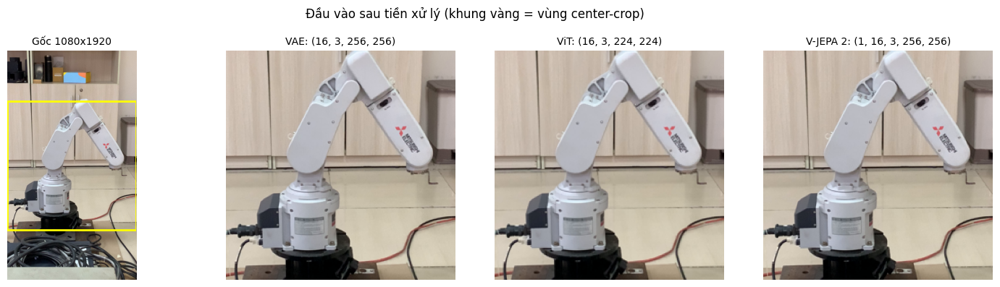

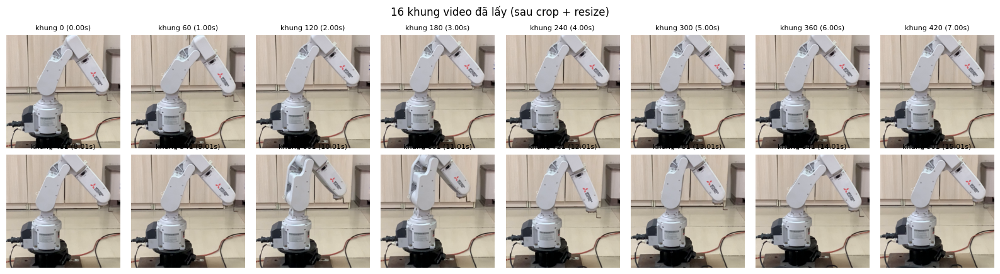

In [27]:
# ---------- Hàm đọc dữ liệu ----------
def load_image(path):
    # exif_transpose: xoay ảnh đúng chiều theo metadata của điện thoại
    return ImageOps.exif_transpose(Image.open(path)).convert("RGB")

def read_video_frames(path, num_frames):
    # Đọc tuần tự video, chỉ giữ lại num_frames khung cách đều nhau
    cap = cv2.VideoCapture(path)
    n, fps = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)), cap.get(cv2.CAP_PROP_FPS)
    keep = set(np.linspace(0, n - 1, num_frames).round().astype(int).tolist())
    frames, idx, i = [], [], 0
    while True:
        ok, f = cap.read()
        if not ok:
            break
        if i in keep:
            frames.append(Image.fromarray(cv2.cvtColor(f, cv2.COLOR_BGR2RGB)))
            idx.append(i)
        i += 1
    cap.release()
    return frames, idx, fps

def center_square(img):
    # Cắt hình vuông lớn nhất ở giữa ảnh
    w, h = img.size; s = min(w, h)
    l, t = (w - s) // 2, (h - s) // 2
    return img.crop((l, t, l + s, t + s))

# ---------- Cấu hình tiền xử lý của từng mô hình ----------
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
PREP = {
    "VAE":      dict(size=256, mean=[0.5] * 3,     std=[0.5] * 3),      # -> [-1, 1]
    "ViT":      dict(size=224, mean=[0.5] * 3,     std=[0.5] * 3),      # theo preprocessor_config.json
    "V-JEPA 2": dict(size=256, mean=IMAGENET_MEAN, std=IMAGENET_STD),   # theo video_preprocessor_config.json
}

def to_tensor(img, size, mean, std):
    # PIL (vuông) -> resize -> tensor (3, size, size) đã chuẩn hoá
    img = img.resize((size, size), Image.BICUBIC)
    x = torch.from_numpy(np.asarray(img, dtype=np.float32) / 255.0).permute(2, 0, 1)
    return (x - torch.tensor(mean)[:, None, None]) / torch.tensor(std)[:, None, None]

def model_frames(m, frames):
    # V-JEPA 2 là mô hình video: ảnh tĩnh được lặp lại thành clip NUM_FRAMES khung giống nhau
    return frames * NUM_FRAMES if (m == "V-JEPA 2" and len(frames) == 1) else frames

def preprocess(frames, model, size=None):
    # frames: list ảnh PIL vuông. Trả về tensor đúng định dạng đầu vào của model
    # size: ghi đè kích thước mặc định (dùng ở Cell 4A để lấy lưới token dày hơn)
    cfg = dict(PREP[model], size=size or PREP[model]["size"])
    x = torch.stack([to_tensor(f, **cfg) for f in model_frames(model, frames)])   # (N, 3, S, S)
    if model == "V-JEPA 2":
        x = x.unsqueeze(0)                                     # (1, T, 3, S, S): 1 clip gồm T khung
    return x

# ---------- Đọc đầu vào đã chọn ----------
if IS_VIDEO:
    raw, frame_idx, fps = read_video_frames(VIDEO_PATH, NUM_FRAMES)
    print(f"Video   : {raw[0].size[0]}x{raw[0].size[1]} @ {fps:.1f} fps, lấy {len(frame_idx)} khung: {frame_idx}")
else:
    raw, frame_idx, fps = [load_image(IMAGE_PATH)], [0], None
    print(f"Ảnh     : {raw[0].size[0]}x{raw[0].size[1]} (W x H)")
frames_sq = [center_square(f) for f in raw]                    # list khung vuông (ảnh: 1 phần tử)
print(f"Crop vuông: {frames_sq[0].size[0]}x{frames_sq[0].size[1]}\n")

x_in = {m: preprocess(frames_sq, m) for m in MODELS}           # tensor đầu vào của từng mô hình
display(pd.DataFrame([dict(model=m, đầu_vào=KIND, shape=tuple(x_in[m].shape),
                           dtype=str(x_in[m].dtype).replace("torch.", ""),
                           min=round(x_in[m].min().item(), 2), max=round(x_in[m].max().item(), 2))
                      for m in MODELS]))

# ---------- Minh hoạ: khung gốc + vùng crop, và đầu vào sau tiền xử lý ----------
def denorm(x, model):
    # Đảo chuẩn hoá để hiển thị lại tensor dưới dạng ảnh
    cfg = PREP[model]
    x = x * torch.tensor(cfg["std"])[:, None, None] + torch.tensor(cfg["mean"])[:, None, None]
    return x.clamp(0, 1).permute(1, 2, 0).numpy()

fig, ax = plt.subplots(1, 4, figsize=(15, 4))
ax[0].imshow(raw[0]); ax[0].set_title(f"Gốc {raw[0].size[0]}x{raw[0].size[1]}")
w, h = raw[0].size; s = min(w, h)
ax[0].add_patch(plt.Rectangle(((w - s) / 2, (h - s) / 2), s, s, fill=False, ec="yellow", lw=2))
for a, m in zip(ax[1:], MODELS):
    xi = x_in[m][0, 0] if m == "V-JEPA 2" else x_in[m][0]
    a.imshow(denorm(xi, m)); a.set_title(f"{m}: {tuple(x_in[m].shape)}")
for a in ax: a.axis("off")
plt.suptitle("Đầu vào sau tiền xử lý (khung vàng = vùng center-crop)"); plt.tight_layout(); plt.show()

if IS_VIDEO:
    fig, ax = plt.subplots(2, NUM_FRAMES // 2, figsize=(16, 4.4))
    for k, a in enumerate(ax.flat):
        a.imshow(denorm(x_in["VAE"][k], "VAE")); a.axis("off")
        a.set_title(f"khung {frame_idx[k]} ({frame_idx[k] / fps:.2f}s)", fontsize=8)
    plt.suptitle(f"{NUM_FRAMES} khung video đã lấy (sau crop + resize)"); plt.tight_layout(); plt.show()

## Cell 2 — Nạp model pretrained, đưa đầu vào vào và xuất latent

* **VAE** (`AutoencoderKL`): encoder trả về phân phối $q(z|x)=\mathcal N(\mu,\sigma^2)$. Ta lấy $z=\mu \cdot 0.18215$ (hệ số scale của Stable Diffusion) ⇒ latent `(B, 4, 32, 32)`: mỗi vị trí trong lưới 32×32 ứng với 1 ô 8×8 pixel, mô tả bằng **4 số**.
* **ViT** (`ViTForImageClassification`): ảnh được cắt thành 14×14 = 196 patch 16×16, mỗi patch → vector 768 chiều, thêm token `[CLS]` ⇒ `last_hidden_state` có shape `(B, 197, 768)`. Token `[CLS]` đi qua bộ phân loại để ra 1000 lớp ImageNet.
* **V-JEPA 2** (`VJEPA2Model`, chỉ dùng **encoder**, bỏ predictor): clip `(1, 16, 3, 256, 256)` được cắt thành *tubelet* 2×16×16 (2 khung × 16×16 pixel) ⇒ $8 \times 16 \times 16 = 2048$ token, mỗi token 1024 chiều ⇒ `(1, 2048, 1024)`.

**Tỉ lệ nén** = số phần tử của đầu vào / số phần tử của latent ( >1 là nén, <1 là "phình" ra).


In [28]:
# ---------- Nạp 3 model từ thư mục local ----------
vae = AutoencoderKL.from_pretrained(MODEL_DIR["VAE"]).to(DEVICE).eval()          # fp32: VAE nhỏ, tránh tràn số fp16
vit = ViTForImageClassification.from_pretrained(MODEL_DIR["ViT"], torch_dtype=DTYPE,
                                                attn_implementation="sdpa").to(DEVICE).eval()
vjepa = VJEPA2Model.from_pretrained(MODEL_DIR["V-JEPA 2"], torch_dtype=DTYPE,
                                    attn_implementation="sdpa").to(DEVICE).eval()

n_params = {  # chỉ đếm phần encoder dùng để tạo latent
    "VAE":      sum(p.numel() for p in vae.encoder.parameters()) + sum(p.numel() for p in vae.quant_conv.parameters()),
    "ViT":      sum(p.numel() for p in vit.vit.parameters()),
    "V-JEPA 2": sum(p.numel() for p in vjepa.encoder.parameters()),
}

# ---------- Hàm mã hoá của từng mô hình ----------
@torch.no_grad()
def encode_vae(x, chunk=4):
    # x: (B,3,256,256) trong [-1,1] -> z: (B,4,32,32). Chia lô nhỏ cho vừa bộ nhớ GPU
    zs = [vae.encode(c.to(DEVICE)).latent_dist.mean * vae.config.scaling_factor for c in x.split(chunk)]
    return torch.cat(zs).float().cpu()

@torch.no_grad()
def encode_vit(x):
    # x: (B,3,224,224) -> tokens (B,197,768) = [CLS] + 196 patch (đã qua LayerNorm cuối)
    # ảnh khác 224: nội suy position embedding (14x14) ra lưới mới
    tokens = vit.vit(pixel_values=x.to(DEVICE, DTYPE),
                     interpolate_pos_encoding=x.shape[-1] != vit.config.image_size).last_hidden_state
    logits = vit.classifier(tokens[:, 0])          # dùng CLS để phân loại (kiểm tra latent có "ý nghĩa")
    return tokens.float().cpu(), logits.float().cpu()

@torch.no_grad()
def encode_vjepa(x):
    # x: (1,T,3,256,256) -> tokens (1, T/2*16*16, 1024); get_vision_features = encoder, bỏ qua predictor
    # RoPE của V-JEPA 2 tính vị trí hàng/cột từ grid_size (mặc định 256/16 = 16) -> phải đặt theo ảnh thật
    for blk in vjepa.encoder.layer:
        blk.attention.grid_size = x.shape[-1] // vjepa.config.patch_size
    return vjepa.get_vision_features(x.to(DEVICE, DTYPE)).float().cpu()

ENCODE = {"VAE": encode_vae, "ViT": lambda x: encode_vit(x)[0], "V-JEPA 2": encode_vjepa}

# ---------- Chạy encode, đo thời gian ----------
for m in MODELS:                                                     # warm-up GPU (lần chạy đầu luôn chậm)
    ENCODE[m](x_in[m][:, :2] if m == "V-JEPA 2" else x_in[m][:1])
latents, infer_ms = {}, {}
for m in MODELS:
    if DEVICE == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    latents[m] = ENCODE[m](x_in[m])
    if DEVICE == "cuda": torch.cuda.synchronize()
    infer_ms[m] = (time.time() - t0) * 1000

# ---------- Bảng kích thước + thống kê latent ----------
def latent_stats(m, z, x):
    # chuẩn L2 trung bình của mỗi token (VAE: vector 4 kênh tại mỗi vị trí)
    tok = z.permute(0, 2, 3, 1).reshape(-1, z.shape[1]) if m == "VAE" else z.reshape(-1, z.shape[-1])
    return {"model": m, "input_shape": tuple(x.shape), "latent_shape": tuple(z.shape),
            "số_token": tok.shape[0], "chiều/token": tok.shape[1], "numel": z.numel(),
            "nén (in/latent)": round(x.numel() / z.numel(), 2),
            "mean": round(z.mean().item(), 3), "std": round(z.std().item(), 3),
            "min": round(z.min().item(), 2), "max": round(z.max().item(), 2),
            "‖token‖ TB": round(tok.norm(dim=1).mean().item(), 2),
            "thời gian (ms)": round(infer_ms[m], 1), "params (M)": round(n_params[m] / 1e6, 1)}

display(pd.DataFrame([latent_stats(m, latents[m], x_in[m]) for m in MODELS]))

# Diễn giải kích thước latent
B = latents["VAE"].shape[0]
print(f"VAE     : {tuple(latents['VAE'].shape)}  -> {B} khung x 4 kênh x lưới 32x32 (mỗi ô = 8x8 pixel)")
print(f"ViT     : {tuple(latents['ViT'].shape)}  -> {B} khung x (1 CLS + 14x14 patch), 768 chiều")
print(f"V-JEPA 2: {tuple(latents['V-JEPA 2'].shape)} -> {NUM_FRAMES}//2={NUM_FRAMES // 2} bước thời gian x 16x16 patch, 1024 chiều")

# ViT là model phân loại: top-5 nhãn dự đoán từ token CLS (video: trung bình xác suất các khung)
_, logits = encode_vit(x_in["ViT"])
top = logits.softmax(-1).mean(0).topk(5)
print(f"\nViT top-5 (ImageNet) cho {'video (TB các khung)' if IS_VIDEO else IMAGE_PATH}:")
for prob, i in zip(top.values, top.indices):
    print(f"   {prob:.3f}  {vit.config.id2label[i.item()]}")

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/587 [00:00<?, ?it/s]

,model,input_shape,latent_shape,số_token,chiều/token,numel,nén (in/latent),mean,std,min,max,‖token‖ TB,thời gian (ms),params (M)
0,VAE,"(16, 3, 256, 256)","(16, 4, 32, 32)",16384,4,65536,48.00,0.191,0.760,-4.96,4.13,1.48,1248.4,34.2
1,ViT,"(16, 3, 224, 224)","(16, 197, 768)",3152,768,2420736,0.99,-0.019,0.907,-6.48,14.34,25.05,1373.7,85.8
2,V-JEPA 2,"(1, 16, 3, 256, 256)","(1, 2048, 1024)",2048,1024,2097152,1.50,0.019,3.024,-37.81,47.59,96.66,3646.6,303.9


VAE     : (16, 4, 32, 32)  -> 16 khung x 4 kênh x lưới 32x32 (mỗi ô = 8x8 pixel)
ViT     : (16, 197, 768)  -> 16 khung x (1 CLS + 14x14 patch), 768 chiều
V-JEPA 2: (1, 2048, 1024) -> 16//2=8 bước thời gian x 16x16 patch, 1024 chiều

ViT top-5 (ImageNet) cho video (TB các khung):
   0.407  joystick
   0.068  spotlight, spot
   0.045  vacuum, vacuum cleaner
   0.027  table lamp
   0.026  hand blower, blow dryer, blow drier, hair dryer, hair drier


## Cell 3 — Xử lý latent

Ba latent có hình dạng rất khác nhau, nên cần đưa về **một định dạng chung** trước khi vẽ và so sánh:

**Lưới token** `(T, H, W, D)`:
   * VAE `(B,4,32,32)` → `(B,32,32,4)` (mỗi ô lưới là 1 "token" 4 chiều).
   * ViT `(B,197,768)` → bỏ `[CLS]` → `(B,14,14,768)`.
   * V-JEPA 2 `(1,2048,1024)` → `(8,16,16,1024)` (thứ tự token là thời gian → hàng → cột).



,model,lưới token,vector toàn cục,PC1,PC1-3,#PC để đạt 90%
0,VAE,"(8, 32, 32, 4)","(8, 4096)",0.500,0.882,4
1,ViT,"(8, 14, 14, 768)","(8, 768)",0.175,0.363,88
2,V-JEPA 2,"(8, 16, 16, 1024)","(8, 1024)",0.120,0.252,>100


VAE tái tạo ảnh từ latent 4x32x32: PSNR = 30.56 dB


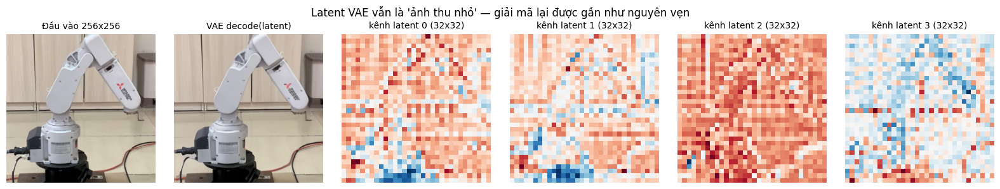

In [29]:
T_STEPS = NUM_FRAMES // 2 if IS_VIDEO else 1   # số bước thời gian sau khi căn (= số tubelet của V-JEPA 2)

def to_grid(m, z, size=None):
    # Latent gốc -> lưới token numpy (T, H, W, D); size = cạnh ảnh đầu vào (mặc định theo PREP)
    if m == "VAE":
        g = z.permute(0, 2, 3, 1)                                   # (B,32,32,4)
    elif m == "ViT":
        p = z[:, 1:]                                                # bỏ CLS -> (B,196,768)
        s = int(math.isqrt(p.shape[1]))
        g = p.reshape(p.shape[0], s, s, p.shape[-1])                # (B,14,14,768)
    else:
        s = (size or PREP[m]["size"]) // vjepa.config.patch_size    # 16
        g = z.reshape(-1, s, s, z.shape[-1])                        # (T/2,16,16,1024)
    return g.numpy().astype(np.float32)

def align_time(m, g, kind):
    # Đưa mọi mô hình về cùng số bước thời gian
    if kind == "image":
        return g.mean(0, keepdims=True)                             # V-JEPA: 8 bước giống nhau -> 1
    if m in ("VAE", "ViT"):
        return g.reshape(-1, 2, *g.shape[1:]).mean(1)               # gộp cặp khung như tubelet
    return g

grids = {m: align_time(m, to_grid(m, latents[m]), KIND) for m in MODELS}

def global_vec(m, g):
    # 1 vector đặc trưng cho mỗi bước thời gian: (T, D_global)
    return g.reshape(len(g), -1) if m == "VAE" else g.mean(axis=(1, 2))

gvec = {m: global_vec(m, grids[m]) for m in MODELS}

# ---------- PCA cho từng mô hình ----------
def center_per_step(g):
    # (T,H,W,D): trừ token trung bình của từng ảnh/khung -> giữ lại khác biệt giữa các patch
    return g - g.mean(axis=(1, 2), keepdims=True)

pca, pca_lo, pca_hi = {}, {}, {}
for m in MODELS:
    g = center_per_step(grids[m]); D = g.shape[-1]
    X = g.reshape(-1, D)                                             # tất cả token của đầu vào
    pca[m] = PCA(n_components=min(D, 100, len(X)), random_state=0).fit(X)
    proj = pca[m].transform(X)[:, :3]
    # dùng phân vị 1%-99% để chuẩn hoá màu, tránh vài token ngoại lai làm "bạc" ảnh
    pca_lo[m], pca_hi[m] = np.percentile(proj, 1, axis=0), np.percentile(proj, 99, axis=0)

def pca_project(m, n=3):
    # lưới (T,H,W,D) -> (T,H,W,n) toạ độ trên n thành phần chính đầu
    g = center_per_step(grids[m]); T, H, W, D = g.shape
    return pca[m].transform(g.reshape(-1, D))[:, :n].reshape(T, H, W, n)

def pca_rgb(m):
    # 3 thành phần chính -> ảnh RGB trong [0,1]
    p = pca_project(m, 3)
    return np.clip((p - pca_lo[m]) / (pca_hi[m] - pca_lo[m] + 1e-8), 0, 1)

rgb = {m: pca_rgb(m) for m in MODELS}

rows = []
for m in MODELS:
    ev = pca[m].explained_variance_ratio_
    rows.append({"model": m, "lưới token": grids[m].shape, "vector toàn cục": gvec[m].shape,
                 "PC1": round(ev[0], 3), "PC1-3": round(ev[:3].sum(), 3),
                 "#PC để đạt 90%": int(np.searchsorted(np.cumsum(ev), 0.9) + 1) if ev.sum() >= 0.9 else f">{len(ev)}"})
display(pd.DataFrame(rows))

# ---------- Giải mã latent VAE -> ảnh (chỉ VAE làm được), dùng khung đầu tiên ----------
with torch.no_grad():
    rec = vae.decode(latents["VAE"][:1].to(DEVICE) / vae.config.scaling_factor).sample.cpu()
orig = x_in["VAE"][:1]
mse = F.mse_loss((rec.clamp(-1, 1) + 1) / 2, (orig + 1) / 2).item()
print(f"VAE tái tạo ảnh từ latent 4x32x32: PSNR = {10 * math.log10(1 / mse):.2f} dB")

fig, ax = plt.subplots(1, 6, figsize=(16, 3))
ax[0].imshow(denorm(orig[0], "VAE")); ax[0].set_title("Đầu vào 256x256")
ax[1].imshow(denorm(rec[0], "VAE")); ax[1].set_title("VAE decode(latent)")
for c in range(4):
    ax[2 + c].imshow(latents["VAE"][0, c], cmap="RdBu_r"); ax[2 + c].set_title(f"kênh latent {c} (32x32)")
for a in ax: a.axis("off")
plt.suptitle("Latent VAE vẫn là 'ảnh thu nhỏ' — giải mã lại được gần như nguyên vẹn"); plt.tight_layout(); plt.show()

## Cell 3B — Nhận diện cách biểu diễn của ba mô hình

Chạy sau Cell 3. Các hình được lưu vào `outputs/latent_identity/` cùng latent gốc `.npz`.



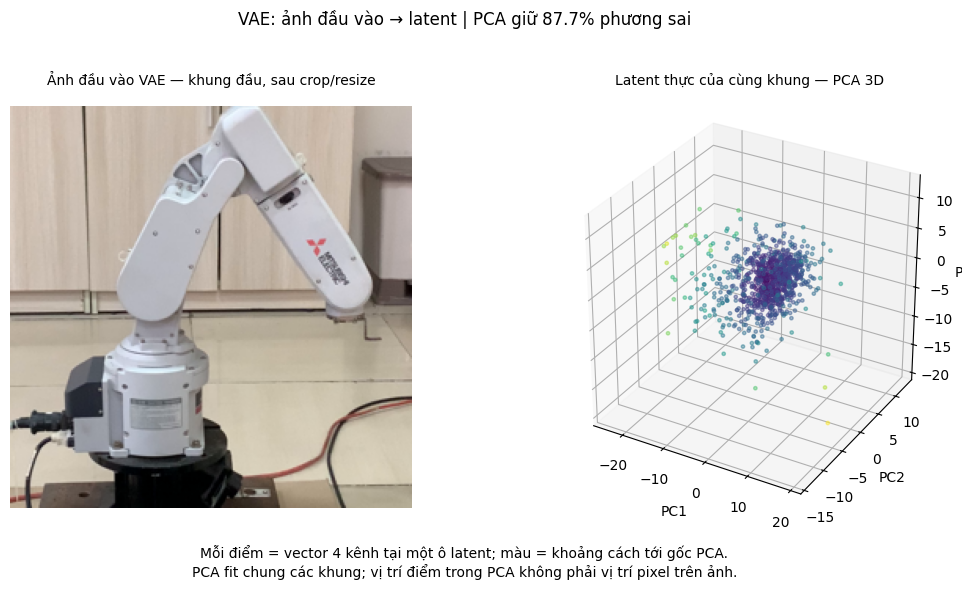

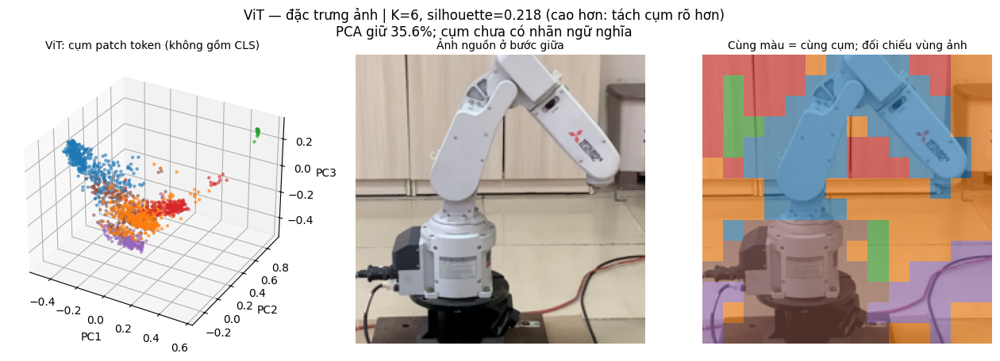

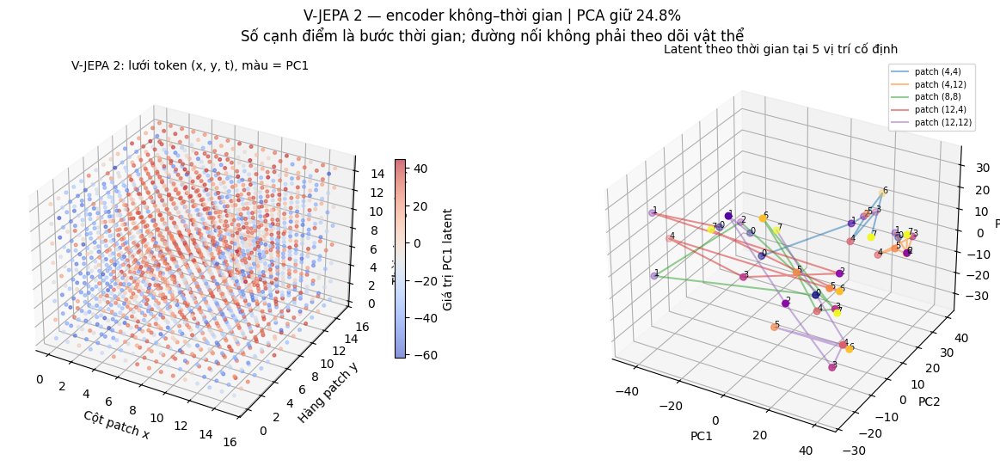

Đã lưu latent gốc, tọa độ và 3 hình vào /home/khanhan/UTE_Master/AI_Programming_ThayDuc/project_middle/outputs/latent_identity


Đã lưu 3 animation GIF và HTML vào /home/khanhan/UTE_Master/AI_Programming_ThayDuc/project_middle/outputs/latent_identity


In [30]:
from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

identity_dir = Path("outputs/latent_identity")
identity_dir.mkdir(parents=True, exist_ok=True)
# Lưu nguyên tensor encoder, không chỉ tọa độ PCA.
np.savez_compressed(identity_dir / "latents_raw.npz",
                    **{m: z.detach().cpu().numpy() for m, z in latents.items()},
                    frame_indices=np.asarray(frame_idx),
                    fps=np.asarray(fps if fps is not None else np.nan),
                    input_kind=np.asarray(KIND))
rng = np.random.default_rng(42)

def save_identity(fig, name):
    fig.savefig(identity_dir / name, dpi=160, bbox_inches="tight")
    plt.show()

# 1. VAE: posterior mean thực, prior tham chiếu; không ép điểm lên mặt cầu.
v = latents["VAE"].permute(0, 2, 3, 1).numpy().reshape(-1, 4)
v = v / float(vae.config.scaling_factor)
vp = PCA(3, random_state=42)
v3 = vp.fit_transform(v)
sel = rng.choice(len(v3), min(3000, len(v3)), replace=False)
# Ảnh nguồn và latent của cùng khung; không dùng Gaussian ngẫu nhiên.
vae_frame_view = 0
vae_grid_shape = latents["VAE"].shape
vae_points_per_frame = vae_grid_shape[2] * vae_grid_shape[3]
frame_points = v3.reshape(vae_grid_shape[0], vae_points_per_frame, 3)[vae_frame_view]
fig = plt.figure(figsize=(13, 6))
image_ax = fig.add_subplot(1, 2, 1)
image_ax.imshow(frames_sq[vae_frame_view].resize((256, 256)))
image_ax.set_title("Ảnh đầu vào VAE — khung đầu, sau crop/resize", pad=15)
image_ax.axis("off")
a = fig.add_subplot(1, 2, 2, projection="3d")
a.scatter(*frame_points.T, c=np.linalg.norm(frame_points, axis=1),
          cmap="viridis", s=6, alpha=.45)
a.set(xlabel="PC1", ylabel="PC2", zlabel="PC3")
a.set_title("Latent thực của cùng khung — PCA 3D", pad=15)
a.set_box_aspect((1, 1, 1))
fig.suptitle(f"VAE: ảnh đầu vào → latent | PCA giữ {vp.explained_variance_ratio_.sum():.1%} phương sai", y=.98)
fig.text(.5, .035,
         "Mỗi điểm = vector 4 kênh tại một ô latent; màu = khoảng cách tới gốc PCA.\n"
         "PCA fit chung các khung; vị trí điểm trong PCA không phải vị trí pixel trên ảnh.",
         ha="center", fontsize=10)
fig.subplots_adjust(top=.82, bottom=.15, wspace=.15)
save_identity(fig, "01_vae_gaussian.png")  # giữ tên file để tương thích output cũ
# Mesh tham chiếu chỉ dùng trong animation VAE phía dưới.
u, w = np.meshgrid(np.linspace(0, 2*np.pi, 36), np.linspace(0, np.pi, 20))

# 2. ViT: cụm trong không gian đặc trưng gốc; màu tương ứng trên ảnh.
K_CLUSTERS = 6  # Có thể đổi; số cụm là lựa chọn phân tích, không phải số lớp tìm được.
g = grids["ViT"]
T, H, W, D = g.shape
features = g.reshape(-1, D)
features = features / np.maximum(np.linalg.norm(features, axis=1, keepdims=True), 1e-8)
k = min(K_CLUSTERS, len(np.unique(features, axis=0)))
km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(features)
labels = km.labels_.reshape(T, H, W)
vp_vit = PCA(3, random_state=42)
coords = vp_vit.fit_transform(features)
score = (silhouette_score(features, km.labels_, sample_size=min(2000, len(features)), random_state=42)
         if 1 < len(np.unique(km.labels_)) < len(features) else float("nan"))
t_view = T // 2
fig = plt.figure(figsize=(16, 5))
a = fig.add_subplot(1, 3, 1, projection="3d")
a.scatter(*coords.T, c=km.labels_, cmap="tab10", vmin=0, vmax=9, s=5, alpha=.5)
a.set(xlabel="PC1", ylabel="PC2", zlabel="PC3", title="ViT: cụm patch token (không gồm CLS)")
source_index = min(2*t_view if IS_VIDEO else 0, len(frames_sq)-1)
image = np.asarray(frames_sq[source_index].resize((224, 224)))
a = fig.add_subplot(1, 3, 2); a.imshow(image); a.axis("off"); a.set_title("Ảnh nguồn ở bước giữa")
a = fig.add_subplot(1, 3, 3); a.imshow(image)
a.imshow(labels[t_view], cmap="tab10", vmin=0, vmax=9, alpha=.55,
         extent=(-.5, 223.5, 223.5, -.5), interpolation="nearest")
a.axis("off"); a.set_title("Cùng màu = cùng cụm; đối chiếu vùng ảnh")
fig.suptitle(f"ViT — đặc trưng ảnh | K={k}, silhouette={score:.3f} (cao hơn: tách cụm rõ hơn)\n"
             f"PCA giữ {vp_vit.explained_variance_ratio_.sum():.1%}; cụm chưa có nhãn ngữ nghĩa")
save_identity(fig, "02_vit_clusters.png")

# 3. V-JEPA: vị trí/thời gian thật và tọa độ latent là hai biểu đồ riêng.
g = grids["V-JEPA 2"]
T, H, W, D = g.shape
jp = PCA(3, random_state=42)
j3 = jp.fit_transform(g.reshape(-1, D)).reshape(T, H, W, 3)
if IS_VIDEO:
    times = np.asarray(frame_idx, dtype=float).reshape(T, -1).mean(1) / fps
else:
    times = np.zeros(T)
tt, yy, xx = np.meshgrid(times, np.arange(H), np.arange(W), indexing="ij")
fig = plt.figure(figsize=(15, 6))
a = fig.add_subplot(1, 2, 1, projection="3d")
sc = a.scatter(xx.ravel(), yy.ravel(), tt.ravel(), c=j3[..., 0].ravel(), cmap="coolwarm", s=7, alpha=.6)
a.set(xlabel="Cột patch x", ylabel="Hàng patch y", zlabel="Thời gian nguồn (s)",
      title="V-JEPA 2: lưới token (x, y, t), màu = PC1")
fig.colorbar(sc, ax=a, shrink=.5, label="Giá trị PC1 latent")
a = fig.add_subplot(1, 2, 2, projection="3d")
for y, x in [(H//4, W//4), (H//4, 3*W//4), (H//2, W//2), (3*H//4, W//4), (3*H//4, 3*W//4)]:
    path = j3[:, y, x]
    a.plot(*path.T, alpha=.5, label=f"patch ({y},{x})")
    a.scatter(*path.T, c=times, cmap="plasma", vmin=times.min(), vmax=max(times.max(), 1e-8), s=30)
    for t in range(T): a.text(*path[t], str(t), fontsize=7)
a.set(xlabel="PC1", ylabel="PC2", zlabel="PC3", title="Latent theo thời gian tại 5 vị trí cố định")
a.legend(fontsize=7)
fig.suptitle(f"V-JEPA 2 — encoder không–thời gian | PCA giữ {jp.explained_variance_ratio_.sum():.1%}\n"
             + ("Số cạnh điểm là bước thời gian; đường nối không phải theo dõi vật thể" if IS_VIDEO
                else "Ảnh tĩnh lặp: không có bằng chứng chuyển động"))
save_identity(fig, "03_vjepa_spacetime.png")
np.savez_compressed(identity_dir / "visualization_data.npz", vae_pca=v3,
                    vit_pca=coords, vit_cluster=labels, vjepa_pca=j3, times_seconds=times)
print("Đã lưu latent gốc, tọa độ và 3 hình vào", identity_dir.resolve())

# ===================== ANIMATION CỦA BA MÔ HÌNH =====================
# Chỉ dùng latent đã có; không encode lại. Các cell phía sau giữ nguyên.
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML, display

ANIM_INTERVAL_MS = 180
plt.rcParams['animation.embed_limit'] = 60

def show_latent_animation(fig, update_fn, count, filename):
    movie = FuncAnimation(fig, update_fn, frames=count,
                          interval=ANIM_INTERVAL_MS, blit=False)
    movie.save(identity_dir / filename, writer=PillowWriter(fps=1000/ANIM_INTERVAL_MS))
    html = movie.to_jshtml()
    (identity_dir / filename.replace('.gif', '.html')).write_text(html, encoding='utf-8')
    plt.close(fig)
    display(HTML(html))
    return movie

def fixed_3d_limits(ax, points):
    lo, hi = points.min(0), points.max(0)
    padding = np.maximum((hi-lo)*.08, .1)
    ax.set_xlim(lo[0]-padding[0], hi[0]+padding[0])
    ax.set_ylim(lo[1]-padding[1], hi[1]+padding[1])
    ax.set_zlim(lo[2]-padding[2], hi[2]+padding[2])
    ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=22, azim=20)

# VAE: PCA chung mọi khung, màu giữ cố định theo vị trí patch.

def make_vae_animation():
    raw_z = latents['VAE'].permute(0, 2, 3, 1).numpy() / float(vae.config.scaling_factor)
    nt, h, w, d = raw_z.shape
    points = vp.transform(raw_z.reshape(-1, d)).reshape(nt, h*w, 3)
    chosen = np.linspace(0, h*w-1, min(1024, h*w)).astype(int)
    colors = plt.get_cmap('turbo')(np.linspace(0, 1, h*w))[chosen]
    fig = plt.figure(figsize=(12, 5))
    image_ax = fig.add_subplot(121)
    image_artist = image_ax.imshow(frames_sq[0].resize((256, 256)))
    image_ax.axis('off')
    ax = fig.add_subplot(122, projection='3d')
    cloud = ax.scatter(*points[0, chosen].T, c=colors, s=7, alpha=.6)
    ax.plot_wireframe(np.sqrt(3)*np.cos(u)*np.sin(w_sphere),
                      np.sqrt(3)*np.sin(u)*np.sin(w_sphere),
                      np.sqrt(3)*np.cos(w_sphere), color='gray', alpha=.15, linewidth=.4)
    fixed_3d_limits(ax, np.vstack([points.reshape(-1, 3), [[-3]*3, [3]*3]]))
    ax.set(xlabel='PC1', ylabel='PC2', zlabel='PC3')
    title = fig.suptitle('')
    def update(i):
        t = i % nt
        image_artist.set_data(np.asarray(frames_sq[t].resize((256, 256))))
        cloud._offsets3d = tuple(points[t, chosen].T)
        stamp = f'{frame_idx[t]/fps:.2f}s' if IS_VIDEO else 'ảnh tĩnh; góc nhìn cố định'
        title.set_text(f'VAE — latent posterior mean | {stamp}\nMàu = vị trí patch; cầu xám = prior tham chiếu')
        return cloud, image_artist, title
    return show_latent_animation(fig, update, nt, '04_vae_animation.gif')

# ViT: dùng từng khung gốc, tránh làm nhòe cụm do trung bình cặp khung.
def make_vit_animation():
    raw_tokens = latents['ViT'][:, 1:].numpy()
    nt, patches, d = raw_tokens.shape
    side = math.isqrt(patches)
    assert side*side == patches
    f = raw_tokens.reshape(-1, d)
    f = f / np.maximum(np.linalg.norm(f, axis=1, keepdims=True), 1e-8)
    clusterer = KMeans(n_clusters=min(K_CLUSTERS, len(np.unique(f, axis=0))),
                      n_init=10, random_state=42).fit(f)
    lab = clusterer.labels_.reshape(nt, side, side)
    projector = PCA(3, random_state=42)
    points = projector.fit_transform(f).reshape(nt, patches, 3)
    fig = plt.figure(figsize=(12, 5))
    image_ax = fig.add_subplot(121)
    image_artist = image_ax.imshow(frames_sq[0].resize((224, 224)))
    overlay = image_ax.imshow(lab[0], cmap='tab10', vmin=0, vmax=9,
                              extent=(-.5, 223.5, 223.5, -.5), alpha=.5, interpolation='nearest')
    image_ax.axis('off'); image_ax.set_title('Cụm token trên ảnh nguồn')
    ax = fig.add_subplot(122, projection='3d')
    cloud = ax.scatter(*points[0].T, c=lab[0].ravel(), cmap='tab10', vmin=0, vmax=9, s=15)
    fixed_3d_limits(ax, points.reshape(-1, 3))
    ax.set(xlabel='PC1', ylabel='PC2', zlabel='PC3')
    title = fig.suptitle('')
    def update(i):
        t = i % nt
        image_artist.set_data(np.asarray(frames_sq[t].resize((224, 224))))
        overlay.set_data(lab[t]); cloud._offsets3d = tuple(points[t].T)
        cloud.set_array(lab[t].ravel())
        stamp = f'{frame_idx[t]/fps:.2f}s' if IS_VIDEO else 'ảnh tĩnh; góc nhìn cố định'
        title.set_text(f'ViT — K-means trên từng khung gốc | {stamp}\nPCA và tâm cụm cố định toàn clip; màu không phải nhãn lớp')
        return cloud, overlay, image_artist, title
    return show_latent_animation(fig, update, nt, '05_vit_animation.gif')

# V-JEPA: ảnh và bản đồ patch chỉ ra không gian, quỹ đạo tích lũy chỉ ra thời gian.
def make_vjepa_animation():
    nt, h, w, _ = j3.shape
    lo, hi = np.percentile(j3, [1, 99], axis=(0, 1, 2))
    maps = np.clip((j3-lo)/(hi-lo+1e-8), 0, 1)
    positions = [(h//4, w//4), (h//2, w//2), (3*h//4, 3*w//4)]
    colors = ['lime', 'magenta', 'cyan']
    fig = plt.figure(figsize=(13, 10))
    source_ax = fig.add_subplot(221)
    source_artist = source_ax.imshow(frames_sq[0].resize((256, 256)))
    source_ax.axis('off'); source_ax.set_title('Ảnh nguồn + vị trí patch cố định')
    map_ax = fig.add_subplot(222)
    map_artist = map_ax.imshow(maps[0], interpolation='nearest')
    map_ax.set(xlabel='Cột patch x (không gian)', ylabel='Hàng patch y (không gian)',
               title='PCA → RGB; cùng phép chiếu, cùng thang màu toàn clip')
    cloud_ax = fig.add_subplot(223, projection='3d')
    cloud = cloud_ax.scatter(*j3[0].reshape(-1, 3).T,
                             c=maps[0].reshape(-1, 3), s=12, alpha=.65)
    fixed_3d_limits(cloud_ax, j3.reshape(-1, 3))
    cloud_ax.set(xlabel='PC1', ylabel='PC2', zlabel='PC3',
                 title='PCA 3D — mọi token tại bước hiện tại')
    ax = fig.add_subplot(224, projection='3d')
    lines, heads = [], []
    for (y, x), color in zip(positions, colors):
        source_ax.plot((x+.5)*256/w, (y+.5)*256/h, 's', color=color, ms=8, fillstyle='none')
        map_ax.plot(x, y, 's', color=color, ms=9, fillstyle='none')
        line, = ax.plot([], [], [], color=color, label=f'patch ({y},{x})')
        head, = ax.plot([], [], [], 'o', color=color)
        lines.append(line); heads.append(head)
    fixed_3d_limits(ax, j3.reshape(-1, 3))
    ax.set(xlabel='PC1', ylabel='PC2', zlabel='PC3', title='Quỹ đạo latent tích lũy theo thời gian')
    ax.legend(fontsize=7)
    if not IS_VIDEO:
        ax.set_title('Các vị trí patch được chọn — ảnh tĩnh')
    fig.subplots_adjust(top=.88, bottom=.07, wspace=.25, hspace=.35)
    title = fig.suptitle('')
    def update(i):
        t = i % nt if IS_VIDEO else 0
        index = min(2*t if IS_VIDEO else 0, len(frames_sq)-1)
        source_artist.set_data(np.asarray(frames_sq[index].resize((256, 256))))
        map_artist.set_data(maps[t])
        cloud._offsets3d = tuple(j3[t].reshape(-1, 3).T)
        cloud.set_facecolors(maps[t].reshape(-1, 3))
        for (y, x), line, head in zip(positions, lines, heads):
            path = j3[:t+1, y, x]
            line.set_data_3d(*path.T)
            head.set_data_3d(*path[-1:].T)
        stamp = f'bước {t+1}/{nt} | tâm tubelet {times[t]:.2f}s' if IS_VIDEO else 'ảnh tĩnh — không có chuyển động thực'
        title.set_text(f'V-JEPA 2 — {stamp}\nMàu RGB = latent; đường màu = vị trí patch cố định, không phải theo dõi vật thể')
        return source_artist, map_artist, cloud, title, *lines, *heads
    return show_latent_animation(fig, update, nt, '06_vjepa_animation.gif')

# w ở phần hình cầu tĩnh là mesh góc, đặt tên riêng tránh nhầm chiều rộng ảnh.
w_sphere = w
vae_animation_3b = make_vae_animation()
vit_animation_3b = make_vit_animation()
vjepa_animation_3b = make_vjepa_animation()
print('Đã lưu 3 animation GIF và HTML vào', identity_dir.resolve())


## Cell 4 — Bản đồ latent chi tiết hơn





VAE: đầu vào 512×512 → latent (8, 64, 64, 4)
ViT: đầu vào 448×448 → latent (8, 28, 28, 768)
V-JEPA 2: đầu vào 512×512 → latent (8, 32, 32, 1024)


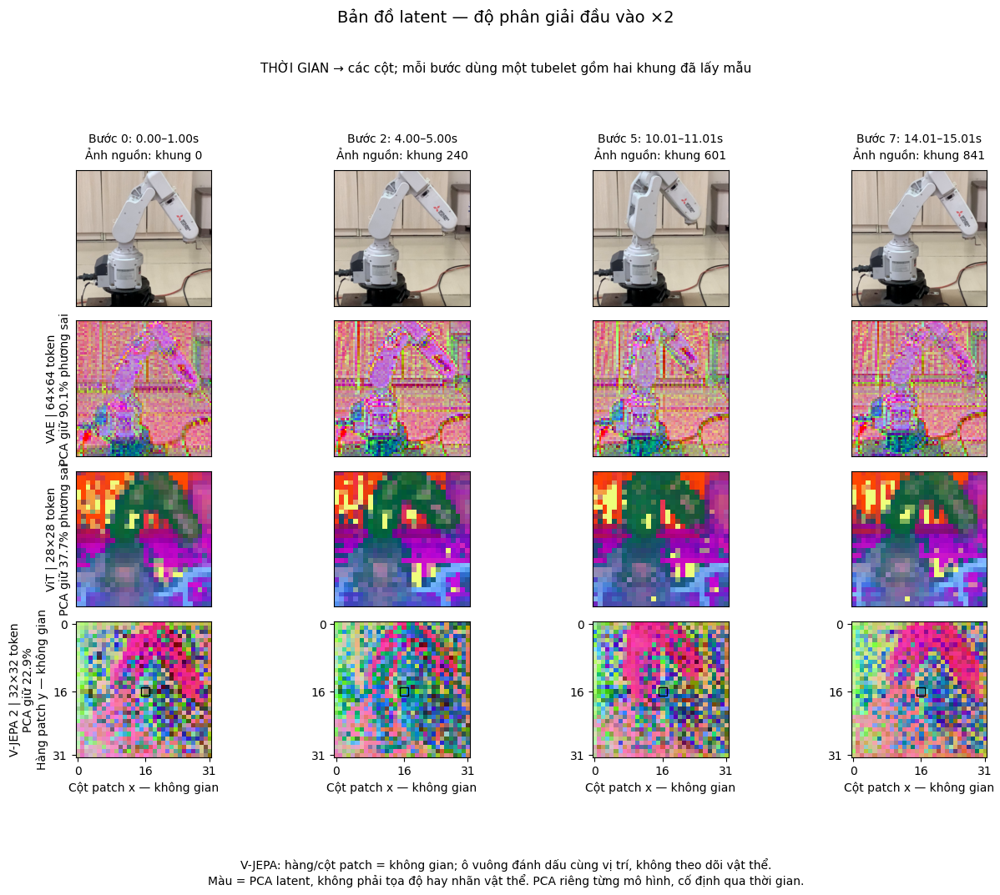

In [31]:
DETAIL_SCALE = 2  # 1: gốc; 2: số token không gian tăng 4 lần.
LATENT_INTERPOLATION = "nearest"
assert isinstance(DETAIL_SCALE, int) and DETAIL_SCALE >= 1

if DETAIL_SCALE == 1:
    detail_grids = grids
else:
    detail_grids = {}
    previous_grid_sizes = [block.attention.grid_size for block in vjepa.encoder.layer]
    try:
        for model in MODELS:
            size = PREP[model]['size'] * DETAIL_SCALE
            if model == 'V-JEPA 2':
                x_detail = preprocess(frames_sq, model, size=size)
                z_detail = encode_vjepa(x_detail)
            else:
                chunks = []
                for frame in frames_sq:
                    x_detail = preprocess([frame], model, size=size)
                    z_frame = encode_vae(x_detail, chunk=1) if model == 'VAE' else encode_vit(x_detail)[0]
                    chunks.append(z_frame)
                z_detail = torch.cat(chunks)
            detail_grids[model] = align_time(model, to_grid(model, z_detail, size=size), KIND)
            expected_side = grids[model].shape[1] * DETAIL_SCALE
            assert detail_grids[model].shape[1:3] == (expected_side, expected_side), f'{model}: lưới không tăng đúng độ phân giải'
            print(f"{model}: đầu vào {size}×{size} → latent {detail_grids[model].shape}")
            del x_detail, z_detail
            if DEVICE == 'cuda': torch.cuda.empty_cache()
    finally:
        for block, original_size in zip(vjepa.encoder.layer, previous_grid_sizes):
            block.attention.grid_size = original_size

os.makedirs('outputs', exist_ok=True)
np.savez_compressed(f'outputs/latent_detail_x{DETAIL_SCALE}.npz',
                    **detail_grids, frame_indices=np.asarray(frame_idx),
                    input_kind=np.asarray(KIND),
                    fps=np.asarray(fps if fps is not None else np.nan))

def step_frame(t):
    return frames_sq[2*t] if IS_VIDEO else frames_sq[0]

rgb_vis, pca_variance_4 = {}, {}
for model in MODELS:
    g = detail_grids[model]
    projector = PCA(3, random_state=0)
    projected = projector.fit_transform(g.reshape(-1, g.shape[-1]))
    lo, hi = np.percentile(projected, [1, 99], axis=0)
    rgb_vis[model] = np.clip((projected-lo)/(hi-lo+1e-8), 0, 1).reshape(*g.shape[:3], 3)
    pca_variance_4[model] = projector.explained_variance_ratio_.sum()

steps = min(len(g) for g in detail_grids.values())
show_t = np.unique(np.linspace(0, steps-1, min(4, steps)).round().astype(int))
if IS_VIDEO:
    fig, axes = plt.subplots(4, len(show_t), figsize=(3.3*len(show_t), 11), squeeze=False)
else:
    fig, axes = plt.subplots(1, 4, figsize=(15, 4), squeeze=False)

for col, t in enumerate(show_t):
    source_ax = axes[0, col] if IS_VIDEO else axes[0, 0]
    source_ax.imshow(step_frame(int(t)).resize((256, 256)))
    if IS_VIDEO:
        pair_indices = np.asarray(frame_idx).reshape(steps, -1)[t]
        start_s, end_s = pair_indices[[0, -1]] / fps
        stamp = f"Bước {t}: {start_s:.2f}–{end_s:.2f}s\nẢnh nguồn: khung {pair_indices[0]}"
    else:
        stamp = "Ảnh đầu vào"
    source_ax.set_title(stamp, pad=10)
    for row, model in enumerate(MODELS, start=1):
        ax = axes[row, col] if IS_VIDEO else axes[0, row]
        ax.imshow(rgb_vis[model][t], interpolation=LATENT_INTERPOLATION, resample=True)
        h, w = detail_grids[model].shape[1:3]
        label = f"{model} | {h}×{w} token\nPCA giữ {pca_variance_4[model]:.1%} phương sai"
        if IS_VIDEO and col == 0: ax.set_ylabel(label, fontsize=10)
        elif not IS_VIDEO: ax.set_title(label, pad=10)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
for col, t in enumerate(show_t):
    ax = axes[3, col] if IS_VIDEO else axes[0, 3]
    h, w = detail_grids['V-JEPA 2'].shape[1:3]
    y, x = h//2, w//2
    ax.plot(x, y, marker='s', markersize=7, markerfacecolor='none', markeredgecolor='black')
    ax.set_xticks([0, w//2, w-1]); ax.set_yticks([0, h//2, h-1])
    ax.set_xlabel('Cột patch x — không gian')
    if col == 0:
        ax.set_ylabel(f"V-JEPA 2 | {h}×{w} token\nPCA giữ {pca_variance_4['V-JEPA 2']:.1%}\nHàng patch y — không gian", fontsize=10)
fig.suptitle(f"Bản đồ latent — độ phân giải đầu vào ×{DETAIL_SCALE}", y=.98, fontsize=14)
if IS_VIDEO:
    fig.text(.5, .91, 'THỜI GIAN → các cột; mỗi bước dùng một tubelet gồm hai khung đã lấy mẫu', ha='center', fontsize=11)
fig.text(.5, .025,
         "V-JEPA: hàng/cột patch = không gian; ô vuông đánh dấu cùng vị trí, không theo dõi vật thể.\n"
         "Màu = PCA latent, không phải tọa độ hay nhãn vật thể. PCA riêng từng mô hình, cố định qua thời gian.",
         ha="center", fontsize=10)
fig.tight_layout(rect=(0, .11, 1, .89 if IS_VIDEO else .94))
os.makedirs("outputs", exist_ok=True)
fig.savefig("outputs/latent_maps_comparison.png", dpi=160, bbox_inches="tight")
plt.show()


## Kết luận 
### 1. VAE:
Latent nén số phần tử đầu vào mà vẫn giữ cấu trúc, đường viền và màu sắc phục vụ tái tạo ảnh.
### 2. ViT:
Latent có xu hướng gom các patch tương đồng thành nhóm
### 3. V-JEPA: 
Latent được tổ chức theo vị trí patch và bước thời gian của clip. Bản đồ PCA và animation cho thấy đặc trưng thay đổi qua các thời điểm.

